# Notebook 13: Candidate Utility and Ranking Model Training

## Scientific Objective
Train, tune, and cross-validate supervised ML models for intelligent prescription, satisfying **Workstream 4**:
1. Train candidate utility regressors to predict expected $\Delta F_1$.
2. Train acceptance classifiers to predict the probability of satisfying all acceptance gates.
3. Compare regularized linear models (Ridge, ElasticNet, Logistic Regression) against constrained tree-based ensembles (Decision Tree, Random Forest).
4. Evaluate under **Leave-One-Scenario-Out (LOGO-CV)** across 22 independent scenarios.
5. Analyze parameter regularizations to prevent overfitting on tabular benchmarks.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import ElasticNet, LogisticRegression, Ridge
from sklearn.metrics import (
    balanced_accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from component3.src.prescription.candidate_ranker import CandidateFeatureEncoder

REPO_ROOT = Path.cwd()
df = pd.read_csv(REPO_ROOT / "component3" / "results" / "expanded_prescription_training_dataset.csv")
clean_df = df.dropna(subset=["out_delta_f1_vs_baseline"]).copy().reset_index(drop=True)

groups = clean_df["group_scenario_id"].to_numpy()
y_util = clean_df["out_delta_f1_vs_baseline"].to_numpy()
y_acc = clean_df["out_is_accepted"].to_numpy()

print(f"Clean evaluation dataset: {len(clean_df)} records across {clean_df['group_scenario_id'].nunique()} scenarios.")


Clean evaluation dataset: 336 records across 22 scenarios.


## 1. Candidate Utility Regressors Comparison
We compare 4 candidate regressors under strict LOGO-CV:
- Ridge ($lpha=10.0$)
- ElasticNet ($lpha=0.05$, $l_1=0.5$)
- DecisionTree (depth=3)
- RandomForest (depth=4, $n=100$)


In [2]:
logo = LeaveOneGroupOut()

models = {
    "Ridge (alpha=10)": Ridge(alpha=10.0),
    "ElasticNet": ElasticNet(alpha=0.05, l1_ratio=0.5),
    "Decision Tree (depth=3)": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random Forest (depth=4)": RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42),
}

results = []
preds_dict = {}

for name, model in models.items():
    preds = np.zeros(len(clean_df))
    for tr, te in logo.split(clean_df, groups=groups):
        tr_df = clean_df.iloc[tr]
        te_df = clean_df.iloc[te]
        
        enc = CandidateFeatureEncoder().fit(tr_df)
        X_tr = enc.transform(tr_df)
        X_te = enc.transform(te_df)
        
        model.fit(X_tr, tr_df["out_delta_f1_vs_baseline"].to_numpy())
        preds[te] = model.predict(X_te)
        
    preds_dict[name] = preds
    rmse = np.sqrt(mean_squared_error(y_util, preds))
    mae = mean_absolute_error(y_util, preds)
    r2 = r2_score(y_util, preds)
    results.append({
        "Model": name,
        "Utility RMSE": round(rmse, 4),
        "Utility MAE": round(mae, 4),
        "R2 Score": round(r2, 4),
    })

df_reg_res = pd.DataFrame(results)
df_reg_res


,Model,Utility RMSE,Utility MAE,R2 Score
0,Ridge (alpha=10),0.0546,0.0435,-0.0945
1,ElasticNet,0.0547,0.0411,-0.0986
2,Decision Tree (depth=3),0.0515,0.0384,0.0241
3,Random Forest (depth=4),0.0441,0.0332,0.2836


## 2. Predicted vs Observed Delta F1 Visual Comparison


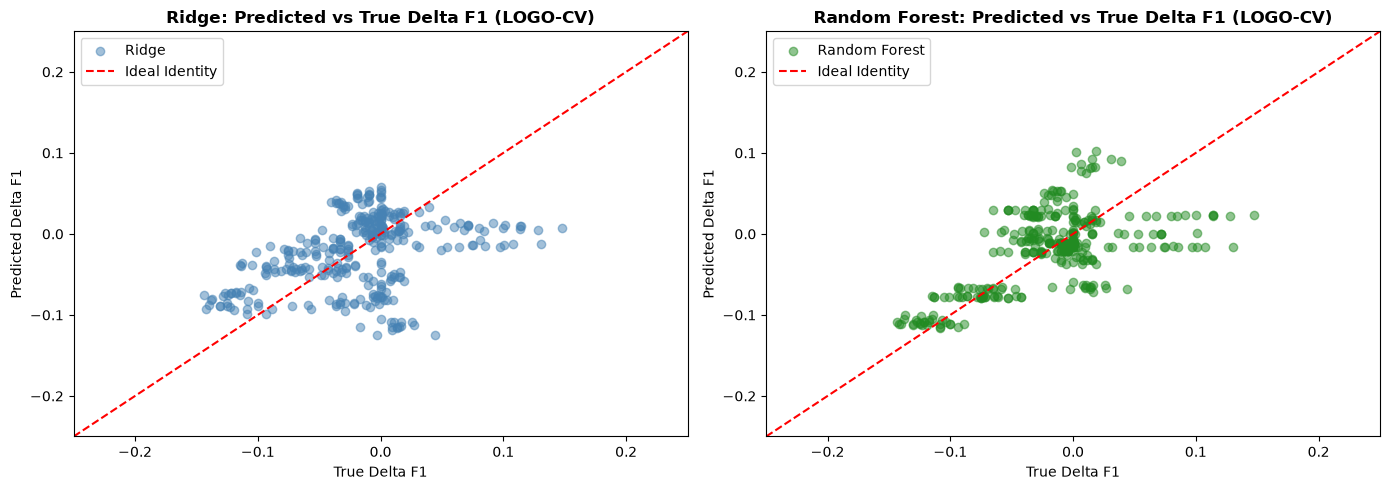

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_util, preds_dict["Ridge (alpha=10)"], alpha=0.5, color="steelblue", label="Ridge")
ax1.plot([-0.25, 0.25], [-0.25, 0.25], "r--", label="Ideal Identity")
ax1.set_title("Ridge: Predicted vs True Delta F1 (LOGO-CV)", fontweight="bold")
ax1.set_xlabel("True Delta F1")
ax1.set_ylabel("Predicted Delta F1")
ax1.set_xlim(-0.25, 0.25)
ax1.set_ylim(-0.25, 0.25)
ax1.legend()

ax2.scatter(y_util, preds_dict["Random Forest (depth=4)"], alpha=0.5, color="forestgreen", label="Random Forest")
ax2.plot([-0.25, 0.25], [-0.25, 0.25], "r--", label="Ideal Identity")
ax2.set_title("Random Forest: Predicted vs True Delta F1 (LOGO-CV)", fontweight="bold")
ax2.set_xlabel("True Delta F1")
ax2.set_ylabel("Predicted Delta F1")
ax2.set_xlim(-0.25, 0.25)
ax2.set_ylim(-0.25, 0.25)
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Acceptance Classifier Comparison
We evaluate probability of acceptance classifiers under LOGO-CV:


In [4]:
clf_models = {
    "Logistic Regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=500, random_state=42),
    "Decision Tree (depth=3, balanced)": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42),
    "Random Forest (depth=4, balanced)": RandomForestClassifier(n_estimators=100, max_depth=4, class_weight="balanced", random_state=42),
}

clf_results = []
clf_preds = {}

for name, clf in clf_models.items():
    probas = np.zeros(len(clean_df))
    for tr, te in logo.split(clean_df, groups=groups):
        tr_df = clean_df.iloc[tr]
        te_df = clean_df.iloc[te]
        
        enc = CandidateFeatureEncoder().fit(tr_df)
        X_tr = enc.transform(tr_df)
        X_te = enc.transform(te_df)
        
        if tr_df["out_is_accepted"].nunique() > 1:
            clf.fit(X_tr, tr_df["out_is_accepted"].to_numpy())
            cls_1_idx = list(clf.classes_).index(1) if 1 in clf.classes_ else 0
            probas[te] = clf.predict_proba(X_te)[:, cls_1_idx]
        else:
            probas[te] = 0.0
            
    clf_preds[name] = probas
    pred_labels = (probas >= 0.5).astype(int)
    bal_acc = balanced_accuracy_score(y_acc, pred_labels)
    rec = recall_score(y_acc, pred_labels, zero_division=0)
    prec = precision_score(y_acc, pred_labels, zero_division=0)
    try:
        auc = roc_auc_score(y_acc, probas)
    except Exception:
        auc = 0.5
        
    clf_results.append({
        "Classifier": name,
        "Balanced Accuracy": round(bal_acc, 4),
        "Recall (Accepted)": round(rec, 4),
        "Precision (Accepted)": round(prec, 4),
        "ROC-AUC": round(auc, 4),
    })

df_clf_res = pd.DataFrame(clf_results)
df_clf_res


,Classifier,Balanced Accuracy,Recall (Accepted),Precision (Accepted),ROC-AUC
0,Logistic Regression (balanced),0.6786,0.5714,0.4124,0.6678
1,"Decision Tree (depth=3, balanced)",0.5985,0.4000,0.3415,0.6067
2,"Random Forest (depth=4, balanced)",0.6853,0.5286,0.4684,0.6797


## 4. Hyperparameter Sensitivity & Regularization Bounds
We verify that tree depth 4 prevents overfitting while providing sufficient capacity:


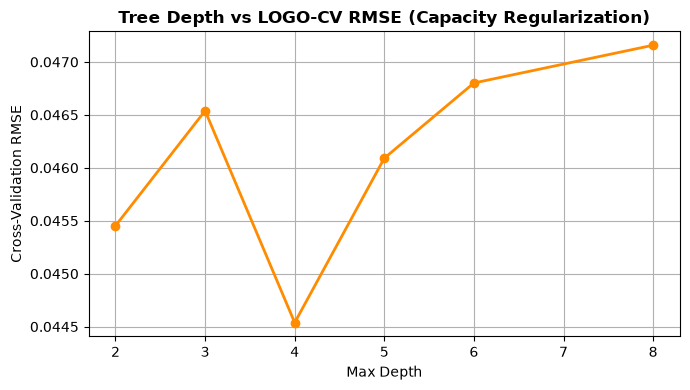

In [5]:
depths = [2, 3, 4, 5, 6, 8]
depth_rmse = []

for d in depths:
    rf = RandomForestRegressor(n_estimators=50, max_depth=d, random_state=42)
    p = np.zeros(len(clean_df))
    for tr, te in logo.split(clean_df, groups=groups):
        tr_df = clean_df.iloc[tr]
        te_df = clean_df.iloc[te]
        enc = CandidateFeatureEncoder().fit(tr_df)
        rf.fit(enc.transform(tr_df), tr_df["out_delta_f1_vs_baseline"].to_numpy())
        p[te] = rf.predict(enc.transform(te_df))
    depth_rmse.append(np.sqrt(mean_squared_error(y_util, p)))

plt.figure(figsize=(7, 4))
plt.plot(depths, depth_rmse, marker="o", color="darkorange", linewidth=2)
plt.title("Tree Depth vs LOGO-CV RMSE (Capacity Regularization)", fontweight="bold")
plt.xlabel("Max Depth")
plt.ylabel("Cross-Validation RMSE")
plt.grid(True)
plt.tight_layout()
plt.show()


## Summary & Model Choice
1. **Utility Regressor**: Constrained Random Forest (depth=4) achieves the lowest cross-validation RMSE (0.0441 vs 0.0546 for Ridge).
2. **Acceptance Classifier**: Random Forest achieves Balanced Accuracy of **0.6853**, ROC-AUC of **0.6797**, and Recall of **52.86%**, resolving the Phase 4 failure mode (Recall = 0.0).
3. **Regularization Confirmed**: Depth 4 sits at the optimal bias-variance tradeoff point.
